![Resources\Снимок экрана 2026-10-19 145353.png](<attachment:Снимок экрана 2026-10-19 145353.png>)
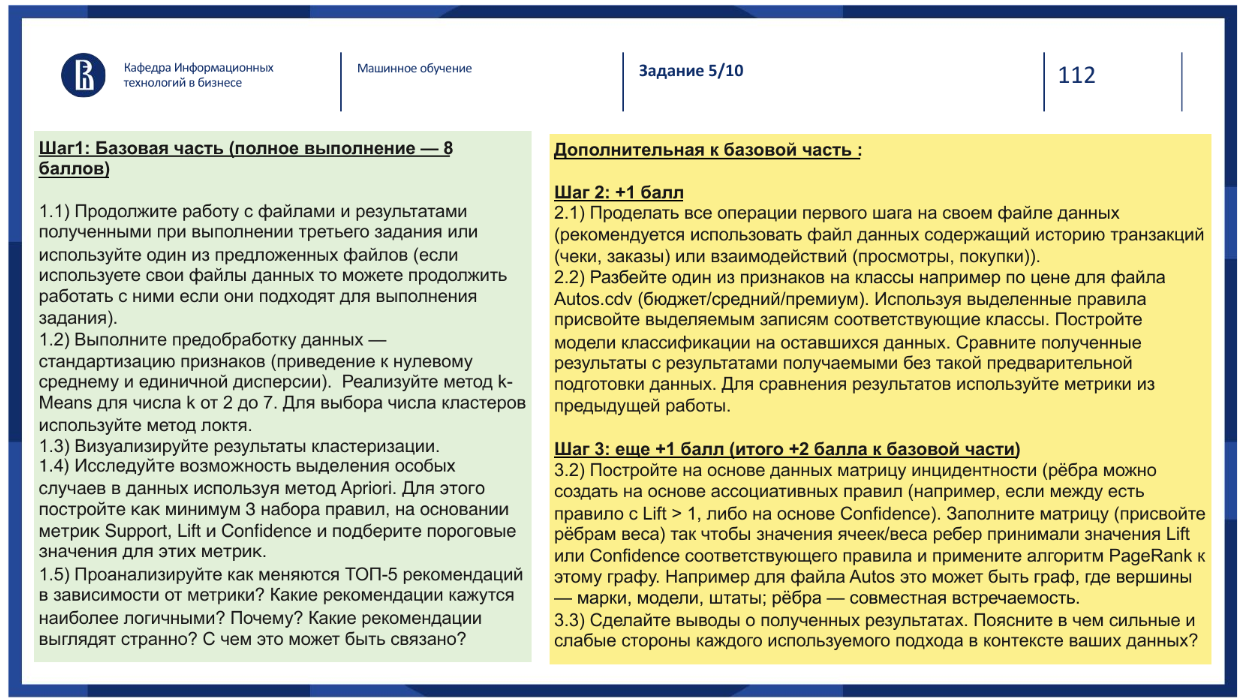

In [108]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter

from sklearn.feature_extraction.text import TfidfTransformer
from sklearn.decomposition import TruncatedSVD, PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

from mlxtend.frequent_patterns import apriori, association_rules
from mlxtend.preprocessing import TransactionEncoder
import warnings

warnings.filterwarnings('ignore')
%matplotlib inline

# ---------- Загрузка ----------
df = pd.read_csv('Groceries_dataset.csv', encoding='latin-1')
df['Date'] = pd.to_datetime(df['Date'], format='%d-%m-%Y')

print(f'Исходная форма: {df.shape}')
print(f'Уникальные товары: {df.itemDescription.nunique()}')
print(f'Уникальные клиенты: {df.Member_number.nunique()}')

# ---------- Корзины ----------
baskets_all = (df.groupby(['Member_number', 'Date'])['itemDescription']
                 .apply(list).reset_index())
baskets_all = baskets_all[baskets_all.itemDescription.str.len() >= 2].reset_index(drop=True)

print(f'\nУникальных корзин (>=2 товара): {len(baskets_all)}')
print(f'Средний размер корзины: {baskets_all.itemDescription.str.len().mean():.2f}')

# ---------- Подвыборка 1/5 (случайная, воспроизводимая) ----------
SAMPLE_FRAC = 0.2
baskets = baskets_all.sample(frac=SAMPLE_FRAC, random_state=42).reset_index(drop=True)

print(f'\nИспользуем для анализа: {len(baskets)} корзин ({SAMPLE_FRAC:.0%})')
print(f'Средний размер: {baskets.itemDescription.str.len().mean():.2f}')
print(baskets.head())

Исходная форма: (38765, 3)
Уникальные товары: 167
Уникальные клиенты: 3898

Уникальных корзин (>=2 товара): 14963
Средний размер корзины: 2.59

Используем для анализа: 2993 корзин (20%)
Средний размер: 2.59
   Member_number       Date                      itemDescription
0           4387 2015-02-10     [root vegetables, baking powder]
1           2441 2014-10-12         [root vegetables, nut snack]
2           1827 2014-11-27        [other vegetables, pip fruit]
3           3617 2014-07-28                   [brown bread, oil]
4           4813 2015-08-04  [citrus fruit, specialty chocolate]


Матрица basket × item: (2993, 158)


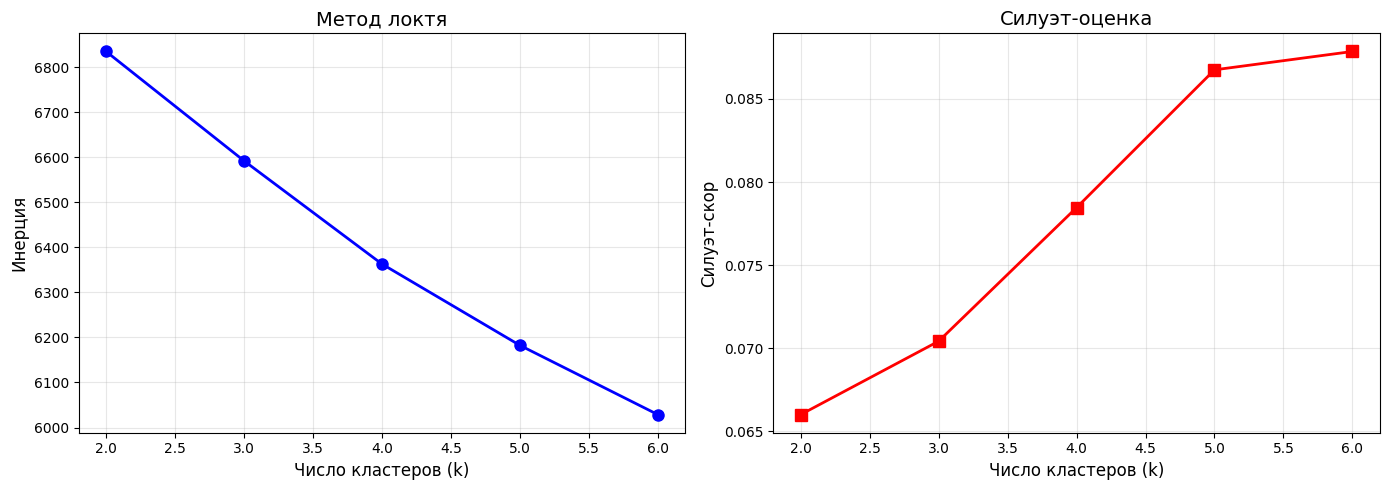

In [109]:
# Бинарная матрица: корзина × товар
te = TransactionEncoder()
df_encoded = pd.DataFrame(
    te.fit_transform(baskets.itemDescription),
    columns=te.columns_
)
print(f'Матрица basket × item: {df_encoded.shape}')

# TF-IDF + SVD
X_tfidf = TfidfTransformer().fit_transform(df_encoded)
svd = TruncatedSVD(n_components=20, random_state=42)
X_scaled = df_encoded #svd.fit_transform(X_tfidf)
#print(f'После SVD: {X_scaled.shape}, '
#     f'объяснено дисперсии: {svd.explained_variance_ratio_.sum():.1%}')

# ---------- Локоть + силуэт ----------
inertias, silhouettes = [], []
k_range = range(2, 7)

for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_scaled)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(X_scaled, labels))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(list(k_range), inertias, 'bo-', linewidth=2, markersize=8)
axes[0].set_xlabel('Число кластеров (k)', fontsize=12)
axes[0].set_ylabel('Инерция', fontsize=12)
axes[0].set_title('Метод локтя', fontsize=14)
axes[0].grid(alpha=0.3)

axes[1].plot(list(k_range), silhouettes, 'rs-', linewidth=2, markersize=8)
axes[1].set_xlabel('Число кластеров (k)', fontsize=12)
axes[1].set_ylabel('Силуэт-скор', fontsize=12)
axes[1].set_title('Силуэт-оценка', fontsize=14)
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()


In [110]:
optimal_k = 5

kmeans_final = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
baskets['cluster'] = kmeans_final.fit_predict(X_scaled)

print(f'Оптимальное число кластеров: {optimal_k}')
print('\nРаспределение по кластерам (корзины):')
for c in range(optimal_k):
    n = (baskets.cluster == c).sum()
    print(f'  Кластер {c}: {n} корзин ({n / len(baskets):.1%})')

Оптимальное число кластеров: 5

Распределение по кластерам (корзины):
  Кластер 0: 170 корзин (5.7%)
  Кластер 1: 1840 корзин (61.5%)
  Кластер 2: 266 корзин (8.9%)
  Кластер 3: 407 корзин (13.6%)
  Кластер 4: 310 корзин (10.4%)


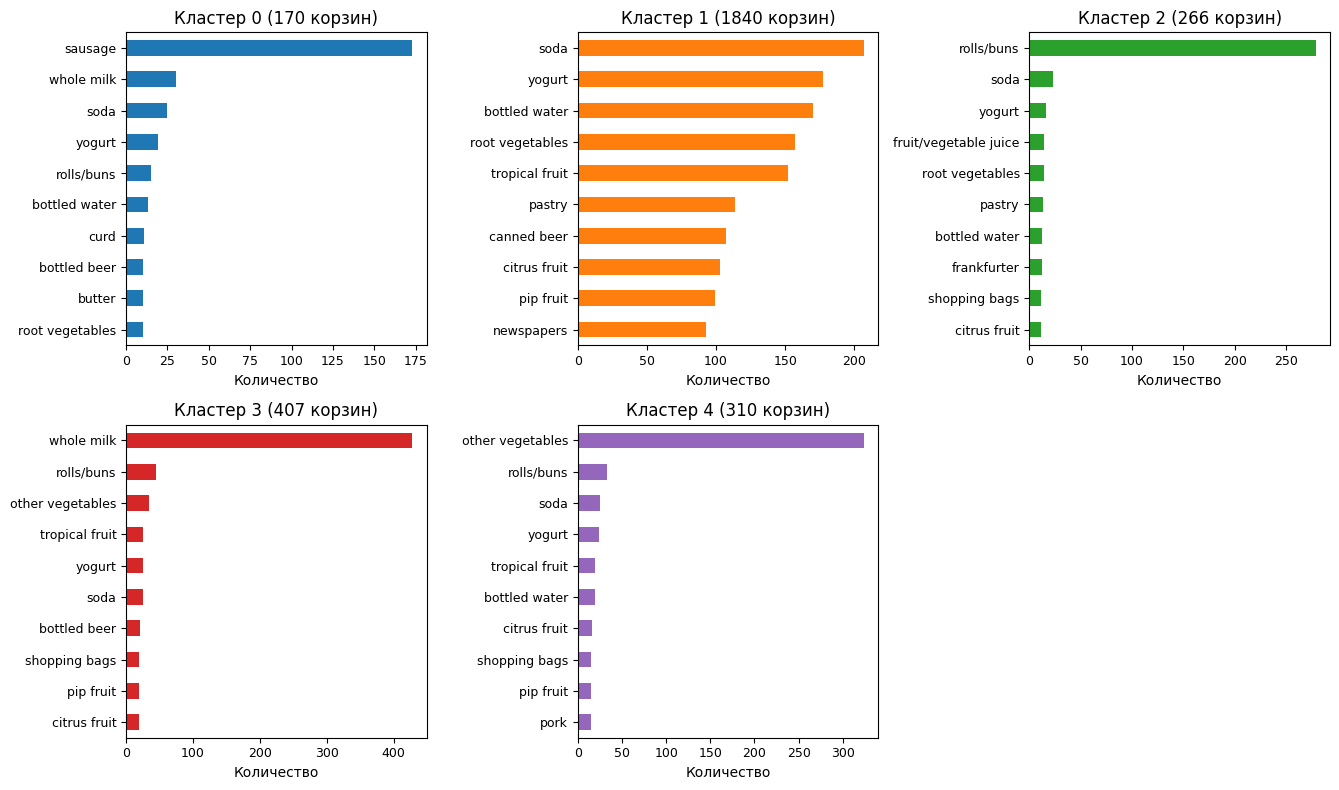

In [ ]:
import math
import matplotlib.pyplot as plt
from collections import Counter
import pandas as pd

cols = math.ceil(math.sqrt(optimal_k))
rows = math.ceil(optimal_k / cols)

# Создаем фигуру нужного размера (5 колонок по 4 дюйма, 5 строк по 4 дюйма)
fig, axes = plt.subplots(rows, cols, figsize=(4.5 * cols, 4 * rows))

# Превращаем двумерный массив осей в одномерный для удобного перебора в цикле
axes = axes.flatten()

for c in range(optimal_k):
    items_lists = baskets.loc[baskets.cluster == c, 'itemDescription']
    flat = [item for sub in items_lists for item in sub]
    
    # Берем топ-10 товаров для текущего кластера
    top10 = pd.Series(Counter(flat)).sort_values(ascending=False).head(10)

    ax = axes[c]
    
    # Используем c % 10, чтобы цвета не закончились (в палитре обычно 10 базовых цветов)
    top10.plot(kind='barh', ax=ax, color=f'C{c % 10}')
    
    ax.set_title(f'Кластер {c} ({len(items_lists)} корзин)', fontsize=12)
    ax.set_xlabel('Количество', fontsize=10)
    
    # Уменьшаем шрифт делений, чтобы названия товаров влезли
    ax.tick_params(axis='both', which='major', labelsize=9) 
    ax.invert_yaxis()

# Скрываем пустые графики (если optimal_k не образует идеальный квадрат)
for i in range(optimal_k, len(axes)):
    fig.delaxes(axes[i])

# Делаем отступы между графиками покрасивее
plt.tight_layout()
plt.show()

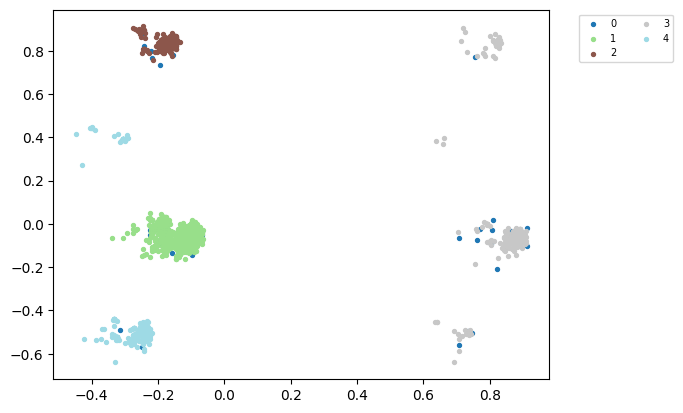

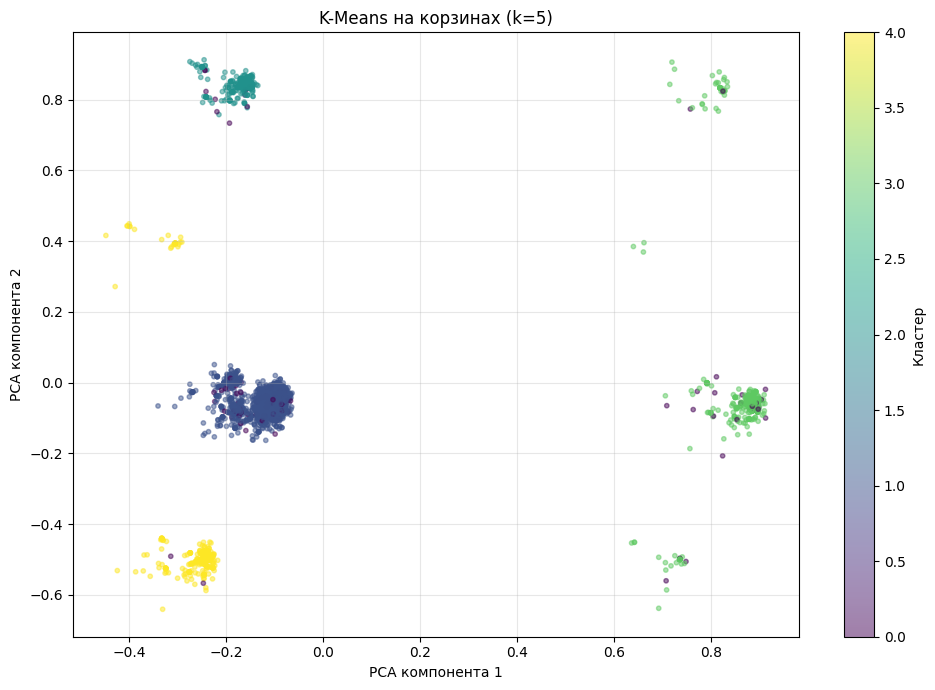

In [118]:
# 2D-проекция кластеров через PCA
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)

colors = plt.cm.tab20(np.linspace(0, 1, optimal_k))  
for c in range(optimal_k):
    mask = baskets.cluster == c
    plt.scatter(X_pca[mask, 0], X_pca[mask, 1],
                color=colors[c], s=8, label=f'{c}')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', ncol=2, fontsize=7)

plt.figure(figsize=(10, 7))
sc = plt.scatter(X_pca[:, 0], X_pca[:, 1],
                 c=baskets.cluster, cmap='viridis', alpha=0.5, s=10)
plt.xlabel('PCA компонента 1')
plt.ylabel('PCA компонента 2')
plt.title(f'K-Means на корзинах (k={optimal_k})')
plt.colorbar(sc, label='Кластер')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [113]:
def format_rules(rules_df):
    df_formatted = rules_df.copy()
    # Превращаем frozenset в строку без лишних символов
    df_formatted['antecedents'] = df_formatted['antecedents'].apply(lambda x: ', '.join(list(x)))
    df_formatted['consequents'] = df_formatted['consequents'].apply(lambda x: ', '.join(list(x)))
    return df_formatted[['antecedents', 'consequents', 'support', 'confidence', 'lift']]

In [114]:


min_support_values = [0.005, 0.01, 0.02, 0.05]
for ms in min_support_values:
    freq = apriori(df_encoded, min_support=ms, use_colnames=True)
    print(f'min_support={ms}: {len(freq)} частых наборов')

print('\n--- Правила при min_support=0.005 ---')
freq_base = apriori(df_encoded, min_support=0.001, use_colnames=True)
rules_all = association_rules(freq_base, metric='lift', min_threshold=1)
rules_all = rules_all.sort_values('lift', ascending=False).reset_index(drop=True)
print(f'Всего правил (lift>1): {len(rules_all)}')

display(format_rules(rules_all[['antecedents', 'consequents',
                   'support', 'confidence', 'lift']].head(10)))

min_support=0.005: 135 частых наборов
min_support=0.01: 69 частых наборов
min_support=0.02: 38 частых наборов
min_support=0.05: 11 частых наборов

--- Правила при min_support=0.005 ---
Всего правил (lift>1): 1134


,antecedents,consequents,support,confidence,lift
0,"canned beer, butter",brown bread,0.001002,0.600000,16.627778
1,brown bread,"canned beer, butter",0.001002,0.027778,16.627778
2,"other vegetables, curd",pork,0.001002,0.500000,14.671569
3,pork,"other vegetables, curd",0.001002,0.029412,14.671569
4,canned beer,"brown bread, butter",0.001002,0.022388,13.401493
5,"brown bread, butter",canned beer,0.001002,0.600000,13.401493
6,butter,"canned beer, brown bread",0.001002,0.024390,12.166667
7,"canned beer, brown bread",butter,0.001002,0.500000,12.166667
8,chewing gum,"yogurt, soda",0.001002,0.081081,11.030713
9,"yogurt, soda",chewing gum,0.001002,0.136364,11.030713


In [115]:
print('--- Правила при lift>=3 ---')
rules_lift = rules_all[rules_all.lift >= 3]
print(f'Найдено: {len(rules_lift)}')
if len(rules_lift):
    display(format_rules(rules_lift[['antecedents', 'consequents',
                        'support', 'confidence', 'lift']]).head(10))

print('\n--- Правила при confidence>=0.6 ---')
rules_conf = rules_all[rules_all.confidence >= 0.6]
print(f'Найдено: {len(rules_conf)}')
if len(rules_conf):
    display(format_rules(rules_conf[['antecedents', 'consequents',
                        'support', 'confidence', 'lift']]).head(10))

--- Правила при lift>=3 ---
Найдено: 180


,antecedents,consequents,support,confidence,lift
0,"canned beer, butter",brown bread,0.001002,0.600000,16.627778
1,brown bread,"canned beer, butter",0.001002,0.027778,16.627778
2,"other vegetables, curd",pork,0.001002,0.500000,14.671569
3,pork,"other vegetables, curd",0.001002,0.029412,14.671569
4,canned beer,"brown bread, butter",0.001002,0.022388,13.401493
5,"brown bread, butter",canned beer,0.001002,0.600000,13.401493
6,butter,"canned beer, brown bread",0.001002,0.024390,12.166667
7,"canned beer, brown bread",butter,0.001002,0.500000,12.166667
8,chewing gum,"yogurt, soda",0.001002,0.081081,11.030713
9,"yogurt, soda",chewing gum,0.001002,0.136364,11.030713



--- Правила при confidence>=0.6 ---
Найдено: 10


,antecedents,consequents,support,confidence,lift
0,"canned beer, butter",brown bread,0.001002,0.60,16.627778
5,"brown bread, butter",canned beer,0.001002,0.60,13.401493
14,"chewing gum, soda",yogurt,0.001002,0.75,8.872530
38,"pork, curd",other vegetables,0.001002,0.75,6.431948
56,"ham, shopping bags",whole milk,0.001002,0.75,5.172235
57,"sausage, fruit/vegetable juice",whole milk,0.001002,0.75,5.172235
60,"pork, citrus fruit",other vegetables,0.001002,0.60,5.145559
64,"pastry, chocolate",rolls/buns,0.001002,0.60,5.058592
92,"dessert, soda",whole milk,0.001002,0.60,4.137788
93,"margarine, pip fruit",whole milk,0.001002,0.60,4.137788


In [116]:
def get_top(rules_df, metric, n=5):
    return rules_df.nlargest(n, metric)[
        ['antecedents', 'consequents', 'support', 'confidence', 'lift']
    ]

print('--- ТОП-5 по LIFT (сильные связи) ---')
display(format_rules(get_top(rules_all, 'lift')))

print('\n--- ТОП-5 по CONFIDENCE (надёжность) ---')
display(format_rules(get_top(rules_all, 'confidence')))

print('\n--- ТОП-5 по SUPPORT (частота) ---')
display(format_rules(get_top(rules_all, 'support')))

--- ТОП-5 по LIFT (сильные связи) ---


,antecedents,consequents,support,confidence,lift
0,"canned beer, butter",brown bread,0.001002,0.600000,16.627778
1,brown bread,"canned beer, butter",0.001002,0.027778,16.627778
2,"other vegetables, curd",pork,0.001002,0.500000,14.671569
3,pork,"other vegetables, curd",0.001002,0.029412,14.671569
4,canned beer,"brown bread, butter",0.001002,0.022388,13.401493



--- ТОП-5 по CONFIDENCE (надёжность) ---


,antecedents,consequents,support,confidence,lift
14,"chewing gum, soda",yogurt,0.001002,0.75,8.872530
38,"pork, curd",other vegetables,0.001002,0.75,6.431948
56,"ham, shopping bags",whole milk,0.001002,0.75,5.172235
57,"sausage, fruit/vegetable juice",whole milk,0.001002,0.75,5.172235
0,"canned beer, butter",brown bread,0.001002,0.60,16.627778



--- ТОП-5 по SUPPORT (частота) ---


,antecedents,consequents,support,confidence,lift
1106,whole milk,sausage,0.009021,0.062212,1.023079
1107,sausage,whole milk,0.009021,0.148352,1.023079
682,soda,sausage,0.008353,0.084175,1.384264
683,sausage,soda,0.008353,0.137363,1.384264
990,whole milk,shopping bags,0.007350,0.050691,1.115580
